# Segmentação de Imagens Acústicas de Poço sem *Ground Truth* (WAID)

**ELE2346 – Deep Learning** · Mestrado em Engenharia Elétrica (Sistemas Inteligentes) · PUC-Rio · 2026.2
Autor: Jorge Alberto Avelino de Souza

**Notebook 07 – Ablação H9: pseudo-rótulo da imagem reconstruída por autoencoder.** Dados: WAID (PETROBRAS, CC BY 4.0), 5 poços.

## Fase 3 – H9
Na referência, o pseudo-rótulo sai do Otsu binário da imagem normalizada. Aqui, um autoencoder de remoção de ruído por poço (Silva, 2026, seção *Interval-wise denoising autoencoder*) reconstrói a imagem, e o Otsu binário da imagem reconstruída gera o pseudo-rótulo. A entrada da U-Net continua a imagem normalizada. Decisões do autor (18/11/2026): um autoencoder por poço, treinado só na imagem do próprio poço (Silva treina por intervalo); Otsu binário (Silva usa Multi-Otsu com 4 classes); leitura pela AUC por patch (README, itens 79 e 80). O IoU sintético não é neutro nesta ablação (U24).

### 7.1 Ambiente: bibliotecas, Google Drive e GPU
Importando as bibliotecas, montando o Drive e instalando a biblioteca de segmentação.

In [1]:
# Importando as bibliotecas usadas no notebook
import sys
from glob import glob
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from google.colab import drive

In [2]:
# Montando o Drive para uso dos arquivos WAID
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
# Instalando a biblioteca com a U-Net e o encoder ResNet18 (o Colab já traz o torch)
!pip install -q segmentation-models-pytorch

### 7.2 Configuração do projeto
Importando as funções de `src` e repetindo a configuração da referência (notebook 04), para que só a mudança da ablação difira.

In [4]:
# Adicionando ao caminho de busca do Python a pasta que contém "src"
sys.path.insert(0, "/content/drive/MyDrive/waid")

# Importando as constantes e as funções do projeto
from src.config import POCOS, NPY_DIR, CARAC_DIR, ANOT_DIR, RES_DIR, ALTURA_PATCH
from src.data.dataset_patches import preparar_dados
from src.train.treino import CFG_PADRAO, rodar_lowo
from src.synth.sintetico import gerar_sintetico
from src.labels.pseudo_ae import treinar_ae, gerar_rotulos_ae, coordenadas_validas
from src.eval.leitura_auc import ler_auc
from src.eval.patches import avaliar_modelos, comparar_pareado

# Escolhendo o dispositivo (GPU, se houver)
DISP = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("dispositivo:", DISP, torch.cuda.get_device_name(0) if DISP.type == "cuda" else "")

# Repetindo a configuração da referência (mesmas épocas, sementes e modelo) e fixando a pasta da H9
CFG = dict(CFG_PADRAO, epocas=10)
MODELO = ["unet_resnet18"]
SEMENTES = [0, 1, 2]
EPOCAS_AE = 60
PASTA_H9 = f"{RES_DIR}/ablacoes/h9_ae"

dispositivo: cuda Tesla T4


### 7.3 Dados e referência
Carregando as imagens, as zonas excluídas (D1), o teste sintético da referência e os escores por patch da referência.

In [5]:
# Carregando os dados (imagens, limiar de Otsu por poço, patches sem sobreposição com os anotados)
imagens, limiares, indice_treino, anot = preparar_dados(NPY_DIR, CARAC_DIR, ANOT_DIR, POCOS, ALTURA_PATCH)

# Carregando as linhas excluídas pela D1 de cada poço
excl = {p: np.load(f"{NPY_DIR}/{p}_excluir_rs.npy") for p in POCOS}

# Gerando o teste sintético da referência (limiar de Otsu da referência; mesmo teste das outras ablações)
sint_ref = {p: gerar_sintetico(imagens, indice_treino, limiares[p], p, altura=ALTURA_PATCH) for p in POCOS}

# Lendo os escores por patch da referência (um arquivo por fold)
esc_ref = pd.concat([pd.read_csv(f) for f in sorted(glob(f"{RES_DIR}/modelos_sint/unet_resnet18_s*_escores.csv"))],
                    ignore_index=True)
print(len(esc_ref), "escores da referência (esperado: 213 = 71 patches × 3 sementes)")

213 escores da referência (esperado: 213 = 71 patches × 3 sementes)


### 7.4 Teste de tempo do autoencoder
Treinando 2 épocas no primeiro poço, em uma pasta de teste, para medir os segundos por época e estimar o treino dos 5 poços. **Parar aqui e decidir** se a H9 segue.

In [10]:
# Treinando 2 épocas no primeiro poço (pasta de teste, separada do treino real)
_, hist_t = treinar_ae(imagens[POCOS[0]], excl[POCOS[0]], DISP, f"{PASTA_H9}_teste_tempo", epocas=EPOCAS_AE,
                       max_epocas_agora=2)

# Estimando o tempo total (segundos por patch da 2ª época × patches de cada poço × épocas)
n_patches = {p: len(coordenadas_validas(excl[p], imagens[p].shape[1])) for p in POCOS}
s_por_patch = hist_t.segundos.iloc[-1] / n_patches[POCOS[0]]
total_min = sum(s_por_patch * n * EPOCAS_AE for n in n_patches.values()) / 60
print("patches por poço:", n_patches)
print(f"estimativa para os 5 poços com {EPOCAS_AE} épocas: {total_min:.0f} min")

  época 5/60: perda 1.665, 10.3 s, 272440 patches
  época 6/60: perda 1.607, 8.6 s, 272440 patches
patches por poço: {'antilope25': 272440, 'antilope37': 216760, 'botorosa47': 197860, 'coala88': 219440, 'tatu22': 204900}
estimativa para os 5 poços com 60 épocas: 35 min


### 7.5 Autoencoders, reconstrução e limiares
Treinando um autoencoder por poço, reconstruindo a imagem e calculando o Otsu binário da imagem reconstruída. Cada poço salva um ponto de controle por época; se o Colab cair, executar de novo continua do ponto.

In [6]:
# Treinando os autoencoders (poços prontos são pulados) e calculando os limiares da imagem reconstruída
rec, limiares_ae, diag = gerar_rotulos_ae(imagens, excl, POCOS, DISP, PASTA_H9, epocas=EPOCAS_AE)
diag.to_csv(f"{RES_DIR}/ablacoes/h9_diagnostico.csv", index=False)
print(diag.to_string(index=False))

      poco  limiar_bruta  limiar_reconstruida  fracao_escura_bruta  fracao_escura_reconstruida  eqm_reconstrucao
antilope25         0.541                0.552                0.035                       0.036           0.00117
antilope37         0.623                0.634                0.106                       0.111           0.00246
botorosa47         0.670                0.690                0.154                       0.172           0.00297
   coala88         0.682                0.697                0.182                       0.205           0.00164
    tatu22         0.760                0.758                0.522                       0.533           0.00094


### 7.6 Conferência antes da U-Net
Conferindo a fração de pixels escuros por poço (a referência ficou entre 0,035 e 0,521, item 74 do README) e olhando um patch por poço: imagem, reconstrução e pseudo-rótulo das duas. **Se algum poço ficar perto de 0% ou de 100%, parar e discutir.**

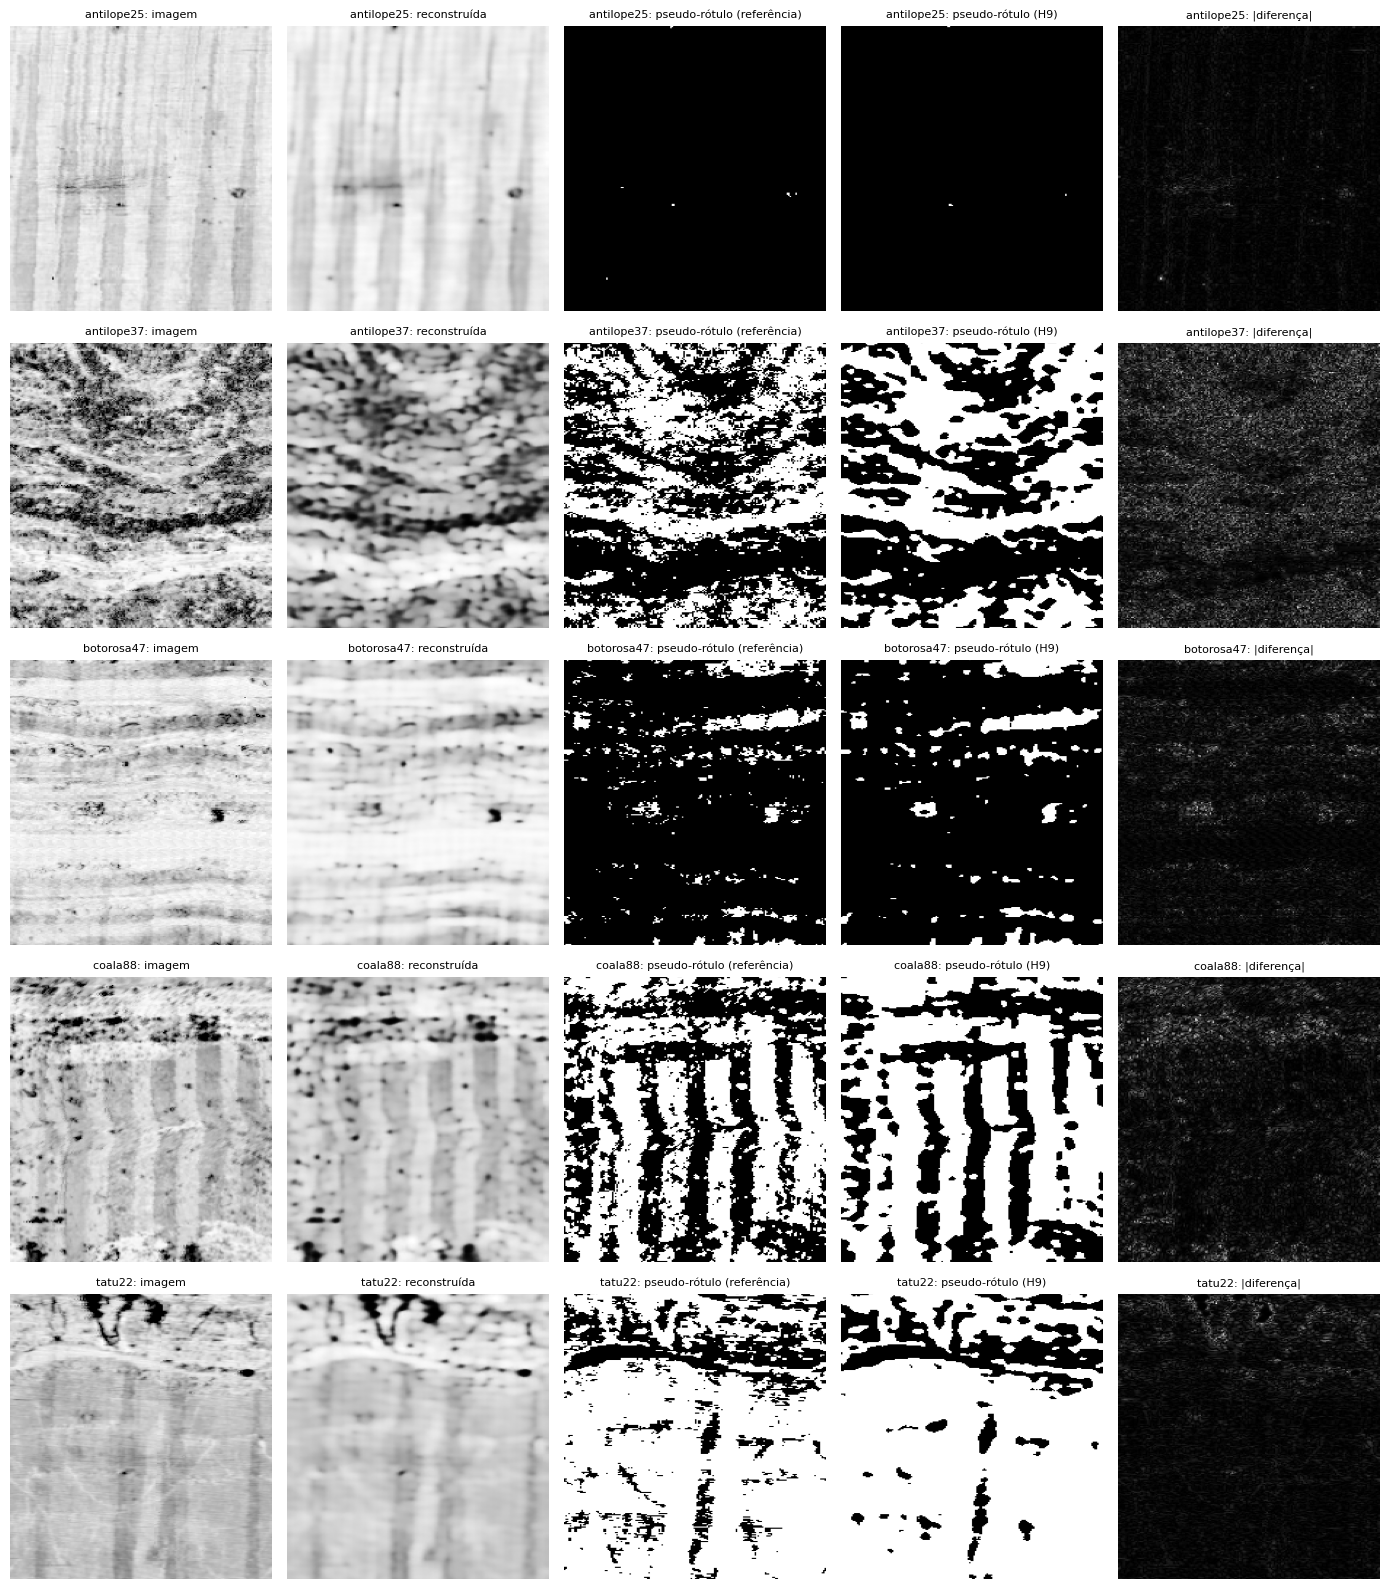

In [11]:
# Desenhando, para cada poço, um patch central com a imagem, a reconstrução e os dois pseudo-rótulos
fig, eixos = plt.subplots(len(POCOS), 5, figsize=(14, 3.2 * len(POCOS)))
for k, p in enumerate(POCOS):
    ini = int(indice_treino[indice_treino.poco == p].linha_ini.median())
    x, r = np.asarray(imagens[p][ini:ini + ALTURA_PATCH], dtype=np.float32), rec[p][ini:ini + ALTURA_PATCH].astype(np.float32)
    for a, im, t in zip(eixos[k], [x, r, x < limiares[p], r < limiares_ae[p], np.abs(x - r)],
                        ["imagem", "reconstruída", "pseudo-rótulo (referência)", "pseudo-rótulo (H9)", "|diferença|"]):
        a.imshow(im, cmap="gray", aspect="auto"); a.set_title(f"{p}: {t}", fontsize=8); a.axis("off")
plt.tight_layout()
plt.savefig(f"{RES_DIR}/ablacoes/h9_diagnostico.png", dpi=120)
plt.show()

### 7.7 H9: treino da U-Net
Treinando a U-Net com o pseudo-rótulo da imagem reconstruída, no teste sintético da referência. Tempo previsto: cerca de 30 min.

In [7]:
# Treinando a U-Net com o pseudo-rótulo do Otsu da imagem reconstruída (entrada: imagem normalizada)
esc_h9, res_h9 = rodar_lowo(MODELO, SEMENTES, POCOS, imagens, indice_treino, anot, limiares_ae, CFG, DISP,
                            f"{RES_DIR}/ablacoes/h9_autoencoder", sint=sint_ref, imagens_rotulo=rec)
res_h9.to_csv(f"{RES_DIR}/ablacoes/h9_resumos.csv", index=False)

### 7.8 Leitura da H9
Aplicando a regra de leitura por AUC (README, item 80). O IoU sintético fica só como informação: ele define as feições pelo limiar da referência e não ordena a H9 (U24).

In [8]:
# Aplicando a regra de leitura por AUC (candidata menos referência)
print("H9 pseudo-rótulo da imagem reconstruída")
print(ler_auc(esc_ref, esc_h9).T.to_string(header=False))

# Mostrando a AUC por semente (referência e H9)
for nome, esc in [("Referência", esc_ref), ("H9", esc_h9)]:
    por_semente, resumo = avaliar_modelos(esc)
    print(nome, "- AUC por semente:", por_semente.auc.tolist())

H9 pseudo-rótulo da imagem reconstruída
n_patches                                    71
auc_ref                                   0.809
auc_cand                                  0.849
dif_pareada                                0.04
ic95_baixo                               -0.007
ic95_alto                                 0.097
dif_media_sementes                        0.037
dp_sementes                               0.027
veredito            não foi detectada diferença
Referência - AUC por semente: [0.783, 0.818, 0.818]
H9 - AUC por semente: [0.837, 0.869, 0.824]


### 7.9 H9 contra o Otsu (AUC pareada)
Comparando a referência e a H9 com o Otsu nos mesmos 71 patches (escore médio das 3 sementes, IC de 95% por *bootstrap* pareado), como na seção 5.17 do notebook 05. Executar de novo a seção 7.2 antes desta.

In [9]:
# Lendo os escores do Otsu e comparando a referência e a H9 com ele
base = pd.read_csv(f"{RES_DIR}/baselines_limiar_escores.csv")
esc_todos = pd.concat([esc_ref.assign(modelo="Referência"), esc_h9.assign(modelo="H9 autoencoder")], ignore_index=True)
print(comparar_pareado(esc_todos, base, "score_soft", "otsu").to_string(index=False))

        modelo  n  auc_modelo  auc_base  diferenca  ic95_baixo  ic95_alto
H9 autoencoder 71       0.849     0.932     -0.083      -0.170     -0.016
    Referência 71       0.809     0.932     -0.123      -0.213     -0.050
